# AML · 01 Exploratory Data Analysis
**Project 18: Water Quality Prediction — Part A, Applied Machine Learning (XGBoost)**

This part of the project estimates the continuous `CCME_Values` index with gradient-boosted trees (XGBoost), compared against a mean baseline and Ridge regression. The neural-network part lives separately in `DL/`.

**Read this first:** the source index is calculated from the same eight measurements. This is an index-emulation experiment, not an independent water-quality or safety prediction. The formula audit below checks this directly.

Run the AML notebooks in order: **01_eda → 02_preprocessing → 03_xgboost_model**.

**Project team**

| Team member | Enrollment number |
|---|---|
| Dhruv Kumar | 2401010152 |
| Ritesh | 2041010383 |
| Yash Kumar | 2401010512 |
| Parul | 2401010321 |
| Punit | 2401010359 |

## 1. Environment
Tested with Python 3.12. Install the dependencies once (see the repository README), then restart the kernel:
```python
%pip install numpy==2.3.4 pandas==2.3.3 scikit-learn==1.7.2 xgboost==3.1.2 matplotlib joblib==1.6.0 ipykernel
```

In [1]:
from pathlib import Path
import json, hashlib, zipfile
import numpy as np
import pandas as pd
from IPython.display import display, Image

# Locate the repository root from either the repo root or the notebook folder.
_here = Path.cwd().resolve()
ROOT = next((p for p in [_here, *_here.parents] if (p / "Datasets" / "Water_Quality_Dataset.zip").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Open this notebook inside the Water_Quality_Prediction repository.")
PART = ROOT / "AML"              # This part of the project
DATA = ROOT / "Datasets"            # Shared source data
CACHE = DATA / "_working"           # Shared extracted CSV; ignored by Git
WORK = PART / "_working"            # Intermediate files for this part; ignored by Git
FIGURES = PART / "figures"
MODELS = PART / "Models"
RESULTS = PART / "Results"
for folder in [CACHE, WORK, FIGURES, MODELS, RESULTS]:
    folder.mkdir(exist_ok=True)
CSV = CACHE / "Combined_dataset.csv"
EXPECTED_SHA256 = "81ced159f465aa5ab004b77130e5f7147c698876ddbf2f97807e31c9d0e8d714"
FEATURES = [
    "Ammonia (mg/l)",
    "Biochemical Oxygen Demand (mg/l)",
    "Dissolved Oxygen (mg/l)",
    "Orthophosphate (mg/l)",
    "pH (ph units)",
    "Temperature (cel)",
    "Nitrogen (mg/l)",
    "Nitrate (mg/l)",
]
SHORT_NAMES = ["Ammonia", "BOD", "Dissolved oxygen", "Orthophosphate", "pH", "Temperature", "Nitrogen", "Nitrate"]
TARGET = "CCME_Values"
OBJECTIVES = np.array([0.5, 6, 14, 0.05, 8.5, 25, 20, 45])
META = ["Country", "Area", "Waterbody Type", "Date"]
BANDS = ["Poor", "Marginal", "Fair", "Good", "Excellent"]


def sha256(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()


def ensure_csv():
    """Extract the unmodified Figshare CSV from the shared ZIP once, then verify it."""
    if not CSV.exists():
        archive = DATA / "Water_Quality_Dataset.zip"
        if archive.exists():
            import shutil
            with zipfile.ZipFile(archive) as z, z.open("Combined_dataset.csv") as src, CSV.open("wb") as dst:
                shutil.copyfileobj(src, dst)
        else:
            import urllib.request
            urllib.request.urlretrieve("https://ndownloader.figshare.com/files/50757321", CSV)
    assert sha256(CSV) == EXPECTED_SHA256, "Dataset checksum differs from the documented release."
    return CSV


def source_formula(frame):
    """Reconstruct released labels, including denominator 12 and upper-only tests.

    Diagnostic only: this intentionally preserves source methodological issues.
    It is NOT an implementation of the official site/time-window CCME standard.
    """
    x = frame[FEATURES].apply(pd.to_numeric, errors="coerce").to_numpy(dtype=float)
    failed = (x > OBJECTIVES).sum(axis=1)
    excursion = np.maximum(x / OBJECTIVES - 1, 0).sum(axis=1)
    f1 = 100 * failed / 12
    nse = excursion / 12
    f3 = nse / (0.01 * nse + 0.01)
    result = 100 - np.sqrt(2 * f1**2 + f3**2) / 1.732
    result[~np.isfinite(x).all(axis=1)] = np.nan
    return result


def quality_features(frame):
    """Mask invalid readings without deleting pollution extremes or guessing units.

    pH outside [0,14] and negative concentrations become missing. Temperature
    outside [-5,50] C is flagged for review, not converted. Every input gets a
    fixed missing/invalid flag, so the model always receives 16 columns.
    """
    absent = set(FEATURES) - set(frame.columns)
    if absent:
        raise ValueError(f"Missing required measurement columns: {sorted(absent)}")
    x = frame[FEATURES].apply(pd.to_numeric, errors="coerce").astype(float)
    x = x.replace([np.inf, -np.inf], np.nan)
    for col in FEATURES:
        if col == "pH (ph units)":
            invalid = ~x[col].between(0, 14)
        elif col == "Temperature (cel)":
            invalid = ~x[col].between(-5, 50)
        else:
            invalid = x[col] < 0
        x.loc[invalid, col] = np.nan
    flags = x.isna().astype(float)
    flags.columns = [f"{col}__missing" for col in FEATURES]
    return pd.concat([x, flags], axis=1)


def dump_json(path, payload):
    Path(path).write_text(json.dumps(payload, indent=2, allow_nan=False) + "\n")

## 2. Load and verify the source
The ZIP in `Datasets/` is only compression: its CSV is the unchanged Figshare release. The extracted copy is cached in `Datasets/_working/` and shared by both project parts.

In [2]:
ensure_csv()
raw = pd.read_csv(CSV)
assert set(META + FEATURES + [TARGET, "CCME_WQI"]).issubset(raw.columns)
print(f"Verified source: {len(raw):,} rows × {len(raw.columns)} columns")
display(raw.head())

Verified source: 2,827,977 rows × 14 columns


,Country,Area,Waterbody Type,Date,Ammonia (mg/l),Biochemical Oxygen Demand (mg/l),Dissolved Oxygen (mg/l),Orthophosphate (mg/l),pH (ph units),Temperature (cel),Nitrogen (mg/l),Nitrate (mg/l),CCME_Values,CCME_WQI
0,Canada,SE649035-145565,River,12-01-1974,0.059248,1.30,8.1500,0.011917,8.07500,9.885,0.343917,11.73155,100.0,Excellent
1,Canada,SE649035-145565,River,12-01-1975,0.039821,1.38,7.8000,0.009417,7.73333,10.150,0.449083,11.82009,100.0,Excellent
2,Canada,SE649035-145565,River,12-01-1976,0.031341,2.23,7.8000,0.011000,7.46667,10.235,0.220750,14.87472,100.0,Excellent
3,Canada,SE649035-145565,River,12-01-1977,0.020501,1.61,8.1500,0.012333,7.78333,11.116,0.572250,15.89293,100.0,Excellent
4,Canada,SE649035-145565,River,12-01-1978,0.020023,1.64,4.3708,0.006182,7.10000,7.068,0.371091,15.22888,100.0,Excellent


## 3. Measurements, units and data quality
Concentrations are labelled mg/L, pH is dimensionless and temperature is labelled °C. Turbidity, conductivity and dissolved solids are absent. The delivered file was already harmonized and imputed upstream, so zero missing cells do not imply complete original measurements.

We flag negative concentrations, pH outside [0,14], nonfinite values and temperature outside [-5,50] °C. We preserve pollution extremes and do not guess unit conversions.

In [3]:
def table_audit(raw):
    reconstructed = source_formula(raw)
    error = np.abs(reconstructed - raw[TARGET].to_numpy())
    q = quality_features(raw)
    numeric = raw[FEATURES].apply(pd.to_numeric, errors="coerce")
    return {
        "raw_rows": len(raw),
        "raw_columns": len(raw.columns),
        "country_counts": raw.Country.value_counts().to_dict(),
        "class_counts": raw.CCME_WQI.value_counts().to_dict(),
        "area_counts_by_country": raw.groupby("Country").Area.nunique().to_dict(),
        "missing_as_delivered": raw.isna().sum().to_dict(),
        "invalid_or_missing_by_feature": q[FEATURES].isna().sum().to_dict(),
        "rows_with_quality_flags": int(q[FEATURES].isna().any(axis=1).sum()),
        "feature_summary": json.loads(numeric.describe().to_json()),
        "formula_audit": {
            "denominator": 12,
            "mae": float(np.nanmean(error)),
            "max_absolute_error": float(np.nanmax(error)),
            "fraction_matching_at_1e_7": float(np.mean(error < 1e-7)),
            "finite_reconstructions": int(np.isfinite(reconstructed).sum()),
        },
        "class_threshold_disagreements": int(np.sum(
            pd.cut(raw[TARGET], [-0.001, 45, 65, 80, 95, 100.001], right=False, labels=BANDS)
            .astype(str).to_numpy() != raw.CCME_WQI.to_numpy()
        )),
    }

audit = table_audit(raw)
audit["exact_duplicates_removed"] = int(raw.duplicated().sum())
dump_json(WORK / "data_audit.json", audit)
print("Exact duplicates:", audit["exact_duplicates_removed"])
print("Missing cells as delivered:", int(raw.isna().sum().sum()))
print("Rows with flagged measurements:", audit["rows_with_quality_flags"])
display(raw[FEATURES].describe().T)
display(pd.Series(audit["invalid_or_missing_by_feature"], name="Flagged readings").to_frame())

Exact duplicates: 9971


Missing cells as delivered: 0
Rows with flagged measurements: 6468


,count,mean,std,min,25%,50%,75%,max
Ammonia (mg/l),2827977.0,1.171360,5.668927,-0.005,0.030,0.055,0.317,200.0
Biochemical Oxygen Demand (mg/l),2827977.0,4.886554,16.413632,-2.000,1.600,2.700,2.830,255.0
Dissolved Oxygen (mg/l),2827977.0,10.007978,1.851052,0.000,9.860,10.200,11.000,20.0
Orthophosphate (mg/l),2827977.0,0.710466,2.089436,-0.004,0.040,0.107,0.227,100.0
pH (ph units),2827977.0,7.735931,0.494687,-1.000,7.550,7.780,8.000,30.0
Temperature (cel),2827977.0,11.839341,5.010197,-5.260,8.990,11.460,14.200,98.0
Nitrogen (mg/l),2827977.0,5.209531,6.200423,0.000,0.780,4.000,6.320,46.0
Nitrate (mg/l),2827977.0,4.766794,6.073781,0.000,1.173,4.500,4.940,155.0


,Flagged readings
Ammonia (mg/l),2
Biochemical Oxygen Demand (mg/l),2
Dissolved Oxygen (mg/l),0
Orthophosphate (mg/l),10
pH (ph units),505
Temperature (cel),5980
Nitrogen (mg/l),0
Nitrate (mg/l),0


## 4. Verify what the target means
The released single-row formula uses eight upper-bound objectives `[0.5, 6, 14, 0.05, 8.5, 25, 20, 45]`, a denominator of 12 and `F2 = F1`. The denominator is inferred by exact agreement with the release.

For each row, count failed objectives, sum positive relative excursions, calculate F1/F3 and combine them as in `source_formula`. This differs from official CCME WQI, which requires an assessment period and appropriate objectives. `CCME_WQI` (the class label) is excluded from all model inputs.

In [4]:
display(pd.Series(audit["formula_audit"], name="Full-source formula audit").to_frame())
assert audit["formula_audit"]["fraction_matching_at_1e_7"] == 1.0
print("Every released label reconstructs from its predictors within 1e-7.")

,Full-source formula audit
denominator,1.200000e+01
mae,1.220143e-15
max_absolute_error,2.842171e-14
fraction_matching_at_1e_7,1.000000e+00
finite_reconstructions,2.827977e+06


Every released label reconstructs from its predictors within 1e-7.


## 5. Explore representation and relationships
All charts below are exported to `AML/figures/`.

Matplotlib is building the font cache; this may take a moment.


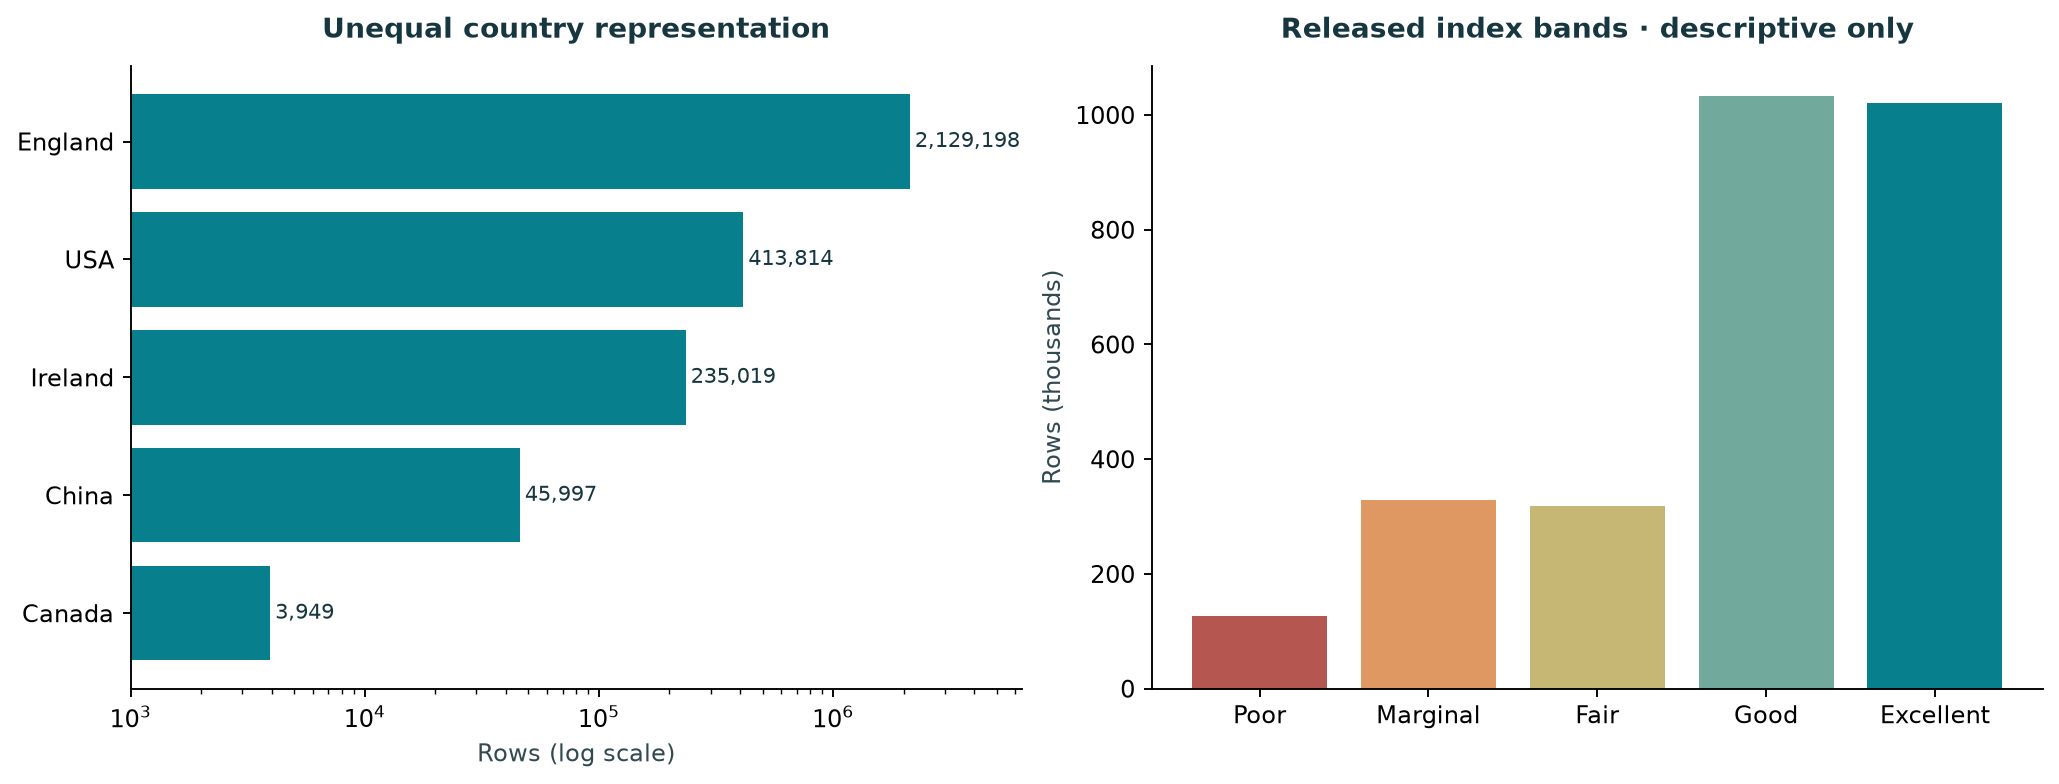

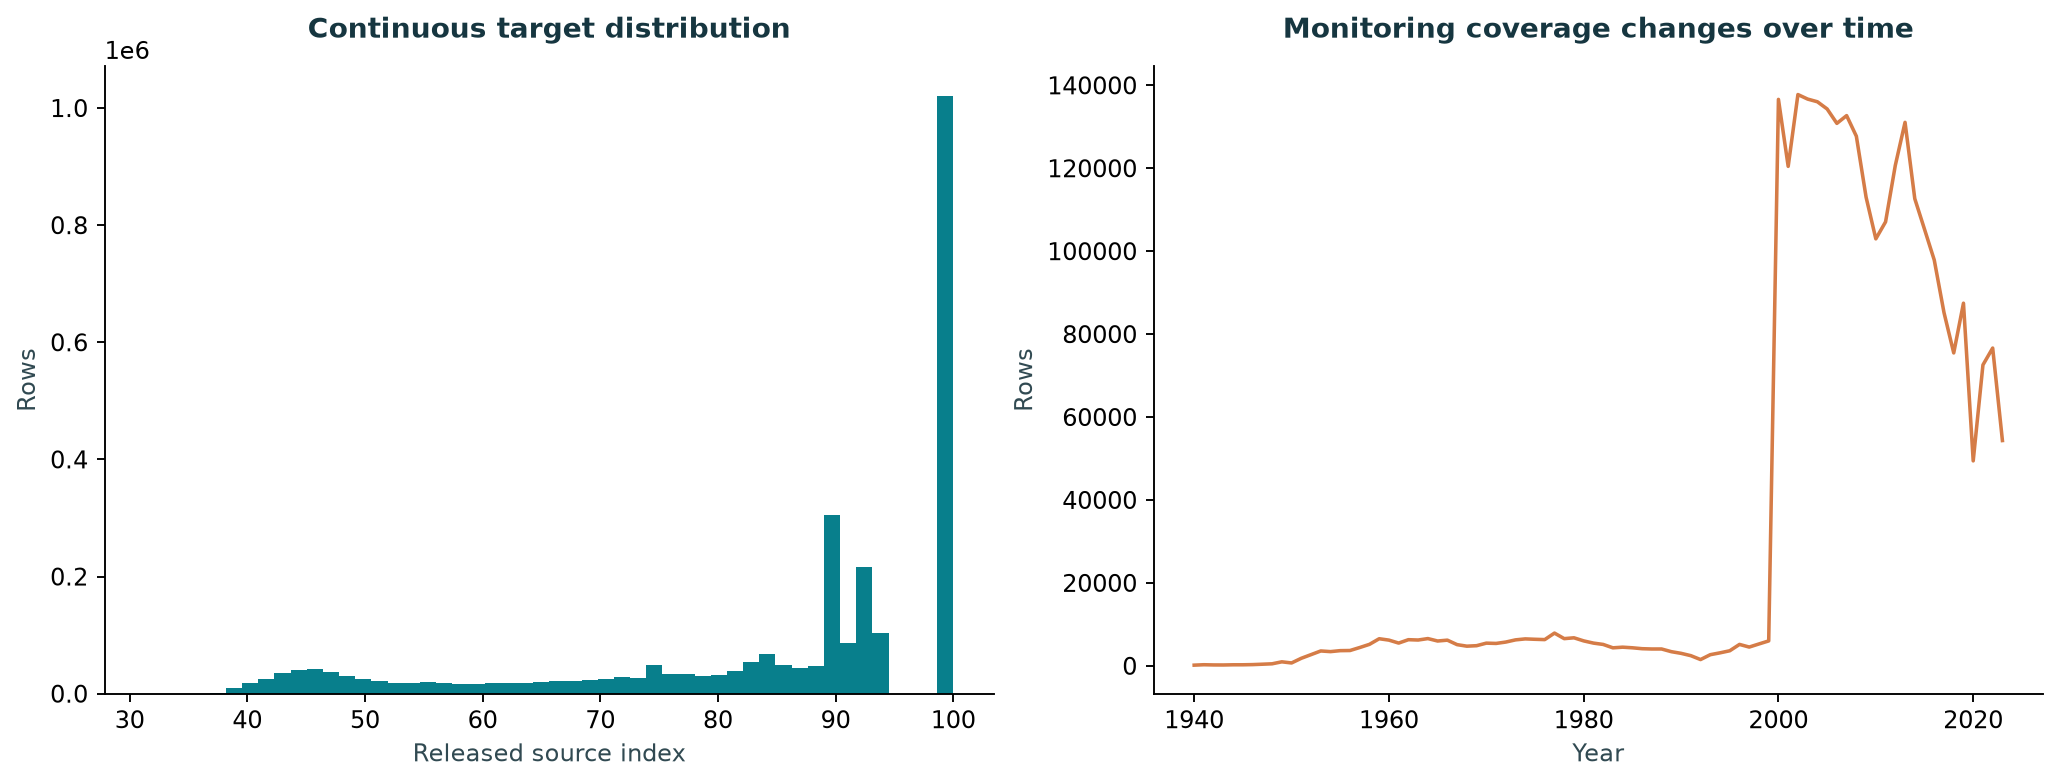

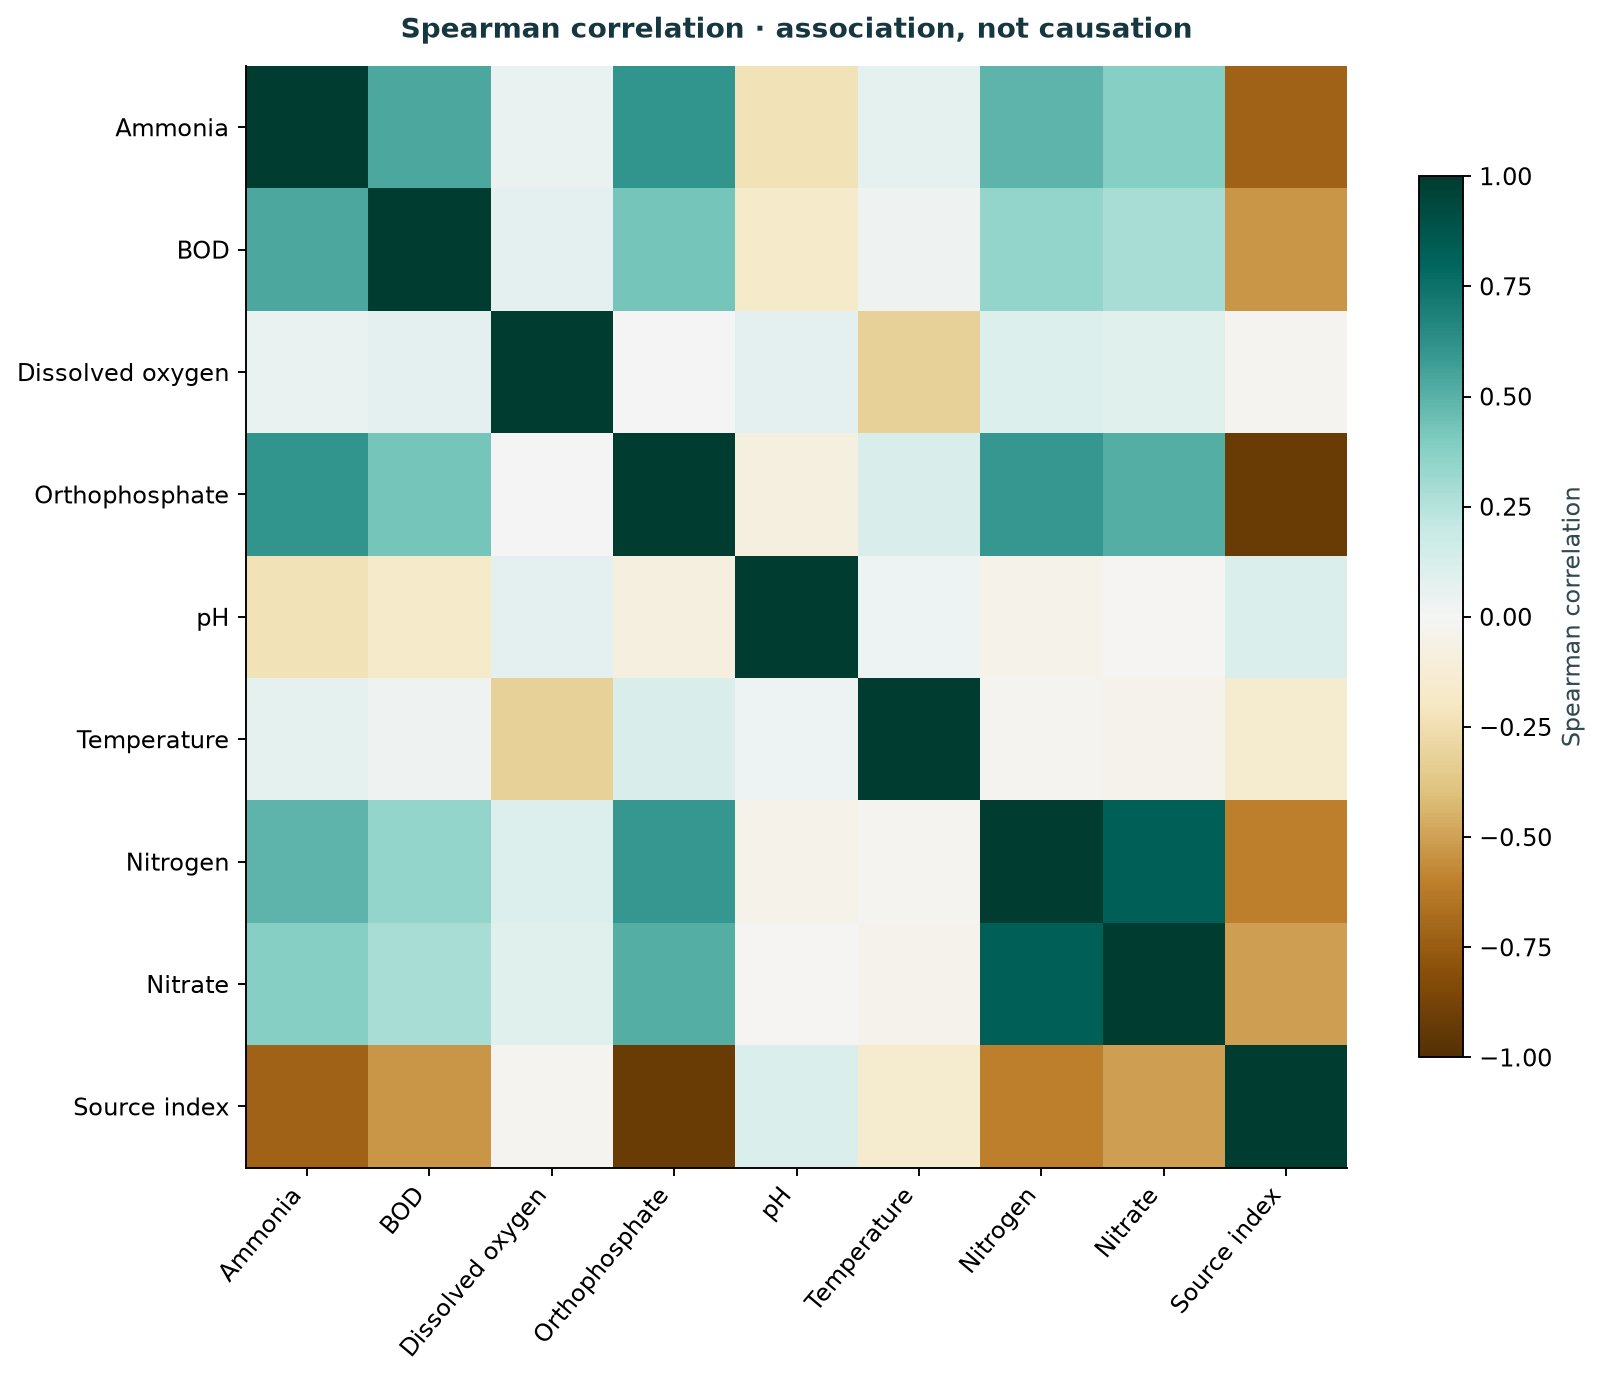

In [5]:
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.labelcolor": "#314a52", "text.color": "#163640",
                     "axes.titleweight": "bold", "axes.titlepad": 12,
                     "grid.color": "#dfe9ea", "axes.axisbelow": True})

def show_figure(fig, name):
    path = FIGURES / name
    fig.savefig(path, dpi=170, bbox_inches="tight", facecolor="white")
    plt.close(fig)
    display(Image(filename=str(path)))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), layout="constrained")
countries = raw.Country.value_counts().sort_values()
axes[0].barh(countries.index, countries.values, color="#087f8c")
axes[0].set(xscale="log", xlabel="Rows (log scale)", title="Unequal country representation")
for i, count in enumerate(countries.values):
    axes[0].text(count * 1.05, i, f"{count:,}", va="center", fontsize=9)
axes[0].set_xlim(1000, countries.max() * 3)
bands = raw.CCME_WQI.value_counts().reindex(BANDS)
axes[1].bar(bands.index, bands.values / 1000, color=["#b55750", "#df9862", "#c6b775", "#71a99d", "#087f8c"])
axes[1].set(ylabel="Rows (thousands)", title="Released index bands · descriptive only")
show_figure(fig, "data_overview.png")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), layout="constrained")
years = pd.to_datetime(raw.Date, format="%d-%m-%Y").dt.year
axes[0].hist(raw[TARGET], bins=50, color="#087f8c")
axes[0].set(xlabel="Released source index", ylabel="Rows", title="Continuous target distribution")
years.value_counts().sort_index().plot(ax=axes[1], color="#d57c47")
axes[1].set(xlabel="Year", ylabel="Rows", title="Monitoring coverage changes over time")
show_figure(fig, "target_and_time.png")

corr = raw[FEATURES + [TARGET]].corr(method="spearman")
fig, ax = plt.subplots(figsize=(10, 8), layout="constrained")
im = ax.imshow(corr, cmap="BrBG", vmin=-1, vmax=1)
labels = SHORT_NAMES + ["Source index"]
ax.set_xticks(range(len(labels)), labels, rotation=50, ha="right")
ax.set_yticks(range(len(labels)), labels)
ax.set_title("Spearman correlation · association, not causation")
fig.colorbar(im, ax=ax, label="Spearman correlation", shrink=.8)
show_figure(fig, "feature_correlations.png")

## Findings and next step
England dominates the records. Coverage varies by year and country. Correlations and later feature importance partly reflect how the target was constructed, so high model accuracy measures formula emulation.

Continue with **02_preprocessing.ipynb**.

Sources: [Karim et al., Figshare v2](https://doi.org/10.6084/m9.figshare.27800394.v2), [CCME WQI manual](https://ccme.ca/en/res/wqimanualen.pdf). Data are reused under CC BY 4.0 with this attribution.